# comets Demo: Torus → CoMET vs PCA/UMAP/CEBRA

This notebook simulates a torus dataset, trains CoMET, benchmarks against PCA/UMAP, and (optionally) CEBRA (per view). Finally, it runs a simple decoding from embeddings → latent angles.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from pathlib import Path
import sys

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    code_dir = p / "code"
    if (code_dir / "comets").exists():
        if str(code_dir) not in sys.path:
            sys.path.insert(0, str(code_dir))
        break

import comets
from comets.encoders import Conv1DEncoder, Conv1DEncoderConfig, SkippedConvEncoder, SkippedConvEncoderConfig, CEBRASKipEncoder
from comets.configs import ModalityConfig, SamplingConfig, TrainingConfig
from comets.heads import TwoLayerMLP, LinearHead, IdentityHead, OneLayerMLP


import umap
import cebra
import torch

In [2]:
# =====================================================
# Static torus with phase jitter (dense mesh coverage)
# =====================================================
# -------------------------
# Parameters
# -------------------------
T = 8000                 # more points for smoother coverage
in_chA, in_chB = 8,16   #informative channels
confA, confB = 2, 3     # confounding channels
noise = 0.3

# -------------------------
# Latent angles with phase jitter
# -------------------------
t = np.arange(T, dtype=np.float32)

# base angular velocities (more cycles)
f1 = 0.04
f2 = 0.04 * np.sqrt(2)   # incommensurate frequencies

# cumulative small random walk for phase jitter
rng = np.random.default_rng(42)
jitter1 = np.cumsum(0.002 * rng.standard_normal(T)).astype(np.float32)
jitter2 = np.cumsum(0.002 * rng.standard_normal(T)).astype(np.float32)

theta1 = (f1 * t + jitter1) % (2 * np.pi)
theta2 = (f2 * t + jitter2) % (2 * np.pi)

# -------------------------
# Static radii
# -------------------------
R_t = np.full(T, 3.0, dtype=np.float32)
r_t = np.full(T, 1.0, dtype=np.float32)

# -------------------------
# Torus trajectory (static radii + jittered phase)
# -------------------------
x = (R_t + r_t * np.cos(theta2)) * np.cos(theta1)
y = (R_t + r_t * np.cos(theta2)) * np.sin(theta1)
z = r_t * np.sin(theta2)
base = np.stack([x, y, z], axis=1)  # [T,3]

# -------------------------
# Nonlinear mixing
# -------------------------
def nonlinear_mix(base, W, nonlin="tanh", noise=0.05):
    X = base @ W
    if nonlin == "tanh":
        X = np.tanh(X)
    elif nonlin == "sin":
        X = np.sin(X)
    elif nonlin == "relu":
        X = np.maximum(0, X)
    return X + noise * np.random.randn(*X.shape)

# -------------------------
# Informative channels
# -------------------------
W_A = np.random.randn(3, in_chA)
W_B = np.random.randn(3, in_chB)

mixA = nonlinear_mix(base, W_A, nonlin="tanh", noise=noise)
mixB = nonlinear_mix(base, W_B, nonlin="sin",  noise=noise)

# -------------------------
# Confounding channels
# -------------------------
confA_white = np.random.randn(T, confA)
confB_white = np.random.randn(T, confB)
confA_drift = np.sin(0.05 * t)[:, None] * np.random.randn(1, confA)
confB_drift = np.cos(0.07 * t)[:, None] * np.random.randn(1, confB)

mixA = np.concatenate([mixA, confA_white, confA_drift], axis=1)
mixB = np.concatenate([mixB, confB_white, confB_drift], axis=1)

# -------------------------
# Random subsampling (simulate droposuts)
# -------------------------
keep_mask = rng.choice([0, 1], size=T, p=[0.6, 0.4])
keep_np = np.sort(np.where(keep_mask == 1)[0])  # preserve time order

mixA = mixA[keep_np]
mixB = mixB[keep_np]
theta1, theta2 = theta1[keep_np], theta2[keep_np]
x, y, z = x[keep_np], y[keep_np], z[keep_np]

# -------------------------
# Convert to torch
# -------------------------
A = torch.tensor(mixA, dtype=torch.float32)
B = torch.tensor(mixB, dtype=torch.float32)

# -------------------------
# Quick check
# -------------------------
print(f"A: {A.shape}, B: {B.shape}")
print(f"θ1, θ2 shapes: {theta1.shape}, {theta2.shape}")


A: torch.Size([3251, 12]), B: torch.Size([3251, 22])
θ1, θ2 shapes: (3251,), (3251,)


In [3]:
# modality configs
modA = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=A.shape[1], emb_dim=32),
    win_len=10
)
modB = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=B.shape[1], emb_dim=32),
    win_len=10
)

sampling = SamplingConfig(
    batch_size=256,
    pos_offset=1,
    # negative_mask_dist=10   # e.g., mask negatives within ±10 timepoints
)

train_cfg = TrainingConfig(epochs=100,lr=1e-3,temperature=1,proj_dim=8,
    alpha_cross=0.7,  # weight cross vs within
    beta=0.9,         # balance A vs B (default equal)
    head_cls=TwoLayerMLP)

In [4]:
model = comets.train(A, modA, B, modB, sampling, train_cfg)

Training: 100%|██████████| 100/100 [00:58<00:00,  1.70it/s, total=4.6864, within=4.6932, cross=4.6834, lr=0.00e+00]


In [5]:

ZA = model.embedA(A)
ZB = model.embedB(B)
print("ZA:", ZA.shape, "ZB:", ZB.shape)

ZA: (3251, 8) ZB: (3251, 8)


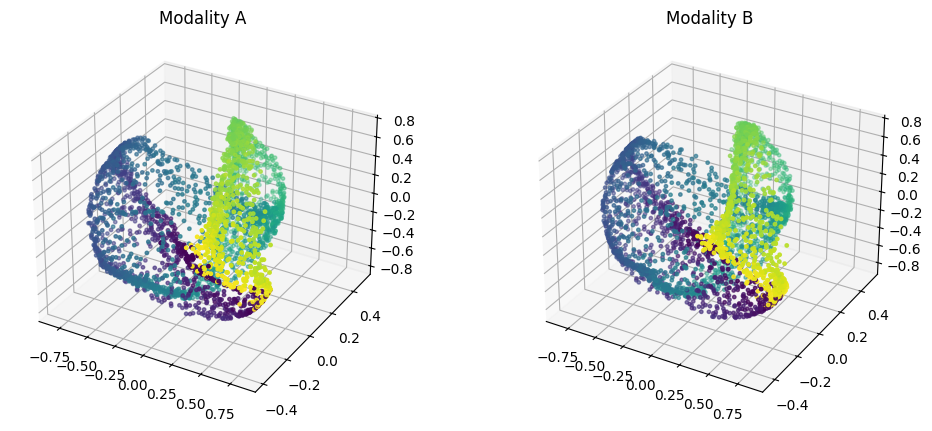

In [6]:
# 5) Visualize embeddings with our built-in viz
comets.plotemb2(
    ZA, ZB,
    color=theta1,               # color points by latent angle
    titles=("Modality A", "Modality B"),
    mode="direct",                 # project to 3D PCA for plotting
    dims=[2,3,5]
)

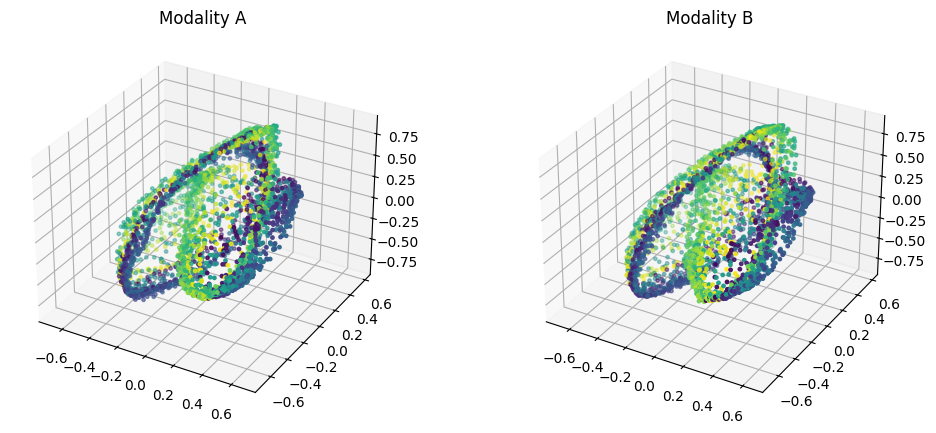

In [7]:
# 5) Visualize embeddings with our built-in viz
comets.plotemb2(
    ZA, ZB,
    color=theta2,               # color points by latent angle
    titles=("Modality A", "Modality B"),
    mode="direct"                  # project to 3D PCA for plotting
)

In [8]:
# 3) Baselines: PCA, UMAP (on each view separately)
# PCA and UMAP baselines
Z1_pca = PCA(n_components=3).fit_transform(A)
Z2_pca = PCA(n_components=3).fit_transform(B)


reducer = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=0)
Z1_umap = reducer.fit_transform(A)
Z2_umap = reducer.fit_transform(B)


f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [9]:
# Optional: CEBRA baseline
cebra_temp = 1
modelA_cebra = cebra.CEBRA(model_architecture='offset10-model',max_iterations=100,
                            batch_size=256, temperature=cebra_temp, verbose = True)
ZA_cebra = modelA_cebra.fit_transform(A)

modelB_cebra = cebra.CEBRA(model_architecture='offset10-model',max_iterations=100,
                            batch_size=256, temperature=cebra_temp
, verbose = True)
ZB_cebra = modelB_cebra.fit_transform(B)

pos: -0.9675 neg:  5.6618 total:  4.6943 temperature:  1.0000: 100%|██████████| 100/100 [00:02<00:00, 41.32it/s]
pos: -0.9348 neg:  5.6308 total:  4.6960 temperature:  1.0000: 100%|██████████| 100/100 [00:01<00:00, 59.82it/s]


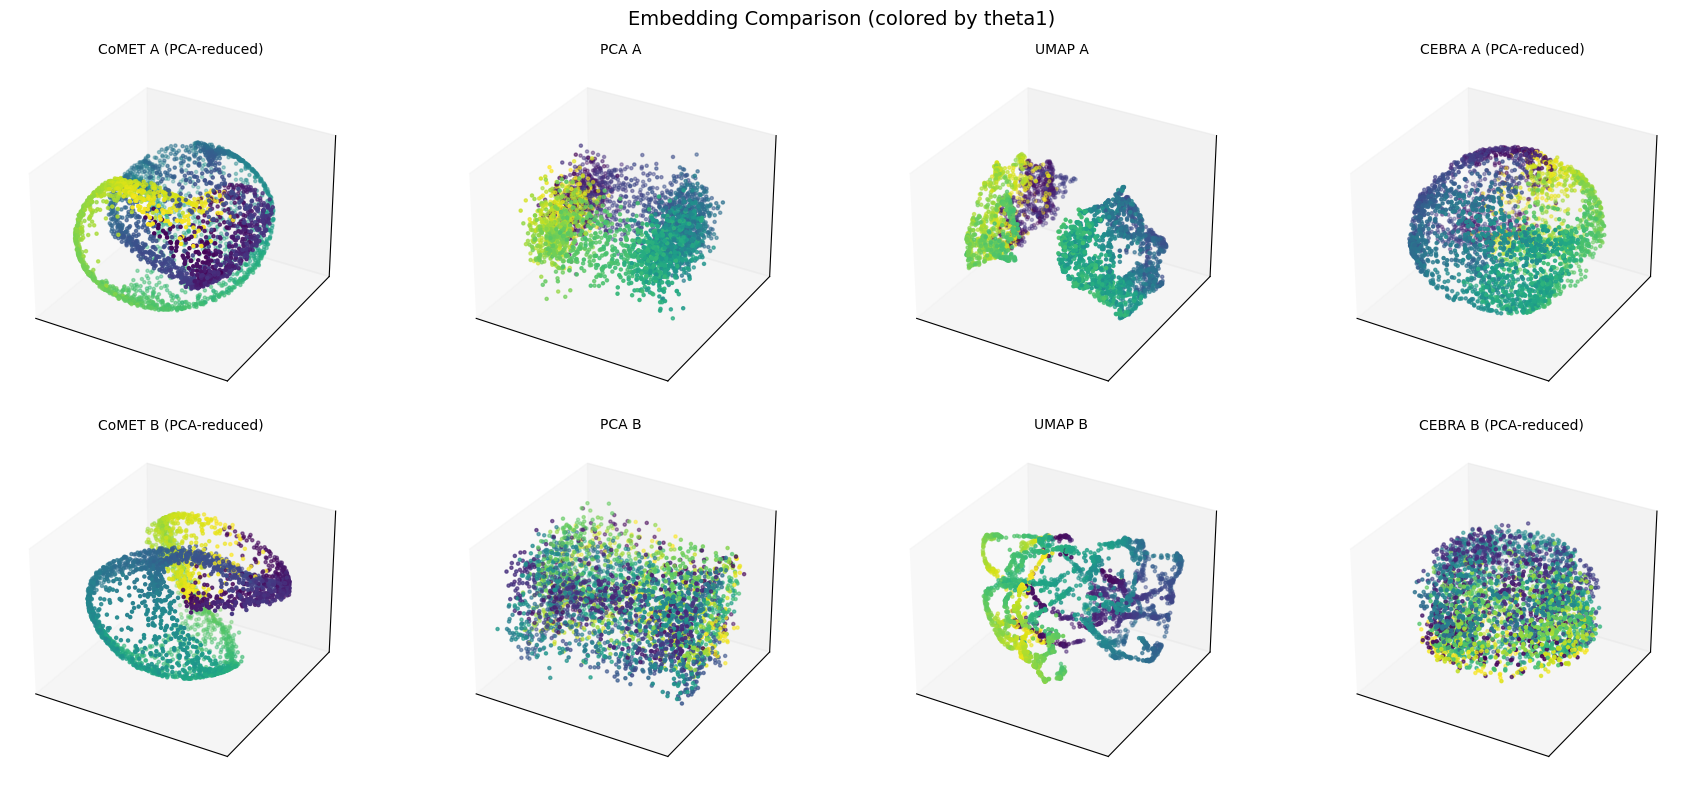

In [10]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa
from sklearn.decomposition import PCA
import numpy as np

# assume you already have:
# ZA, ZB (CoMET)
# ZA_cebra, ZB_cebra (CEBRA)
# Z1_pca, Z2_pca (PCA)
# Z1_umap, Z2_umap (UMAP)
# theta1 (color variable)

def reduce3(Z):
    """Return a 3-D PCA projection regardless of input dim."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z[:, 0], Z[:, 1], Z[:, 2]

# ------------------------------------------
# Create figure: 2 rows x 4 columns
# ------------------------------------------
fig = plt.figure(figsize=(18, 8))

titles_top = ["CoMET A (PCA-reduced)", "PCA A", "UMAP A", "CEBRA A (PCA-reduced)"]
titles_bot = ["CoMET B (PCA-reduced)", "PCA B", "UMAP B", "CEBRA B (PCA-reduced)"]

# Apply PCA to CoMET / CEBRA before plotting
ZA_red = PCA(n_components=3).fit_transform(ZA)
ZB_red = PCA(n_components=3).fit_transform(ZB)
ZA_cebra_red = PCA(n_components=3).fit_transform(ZA_cebra)
ZB_cebra_red = PCA(n_components=3).fit_transform(ZB_cebra)

datasets_top = [ZA_red, Z1_pca, Z1_umap, ZA_cebra_red]
datasets_bot = [ZB_red, Z2_pca, Z2_umap, ZB_cebra_red]

for i in range(4):
    # ---- Top row (view A) ----
    ax = fig.add_subplot(2, 4, i + 1, projection='3d')
    X, Y, Z = reduce3(datasets_top[i])
    ax.scatter(X, Y, Z, c=theta1, cmap='viridis', s=5)
    ax.set_title(titles_top[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

    # ---- Bottom row (view B) ----
    ax = fig.add_subplot(2, 4, i + 5, projection='3d')
    X, Y, Z = reduce3(datasets_bot[i])
    ax.scatter(X, Y, Z, c=theta1, cmap='viridis', s=5)
    ax.set_title(titles_bot[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

fig.suptitle("Embedding Comparison (colored by theta1)", fontsize=14)
plt.tight_layout()
plt.show()


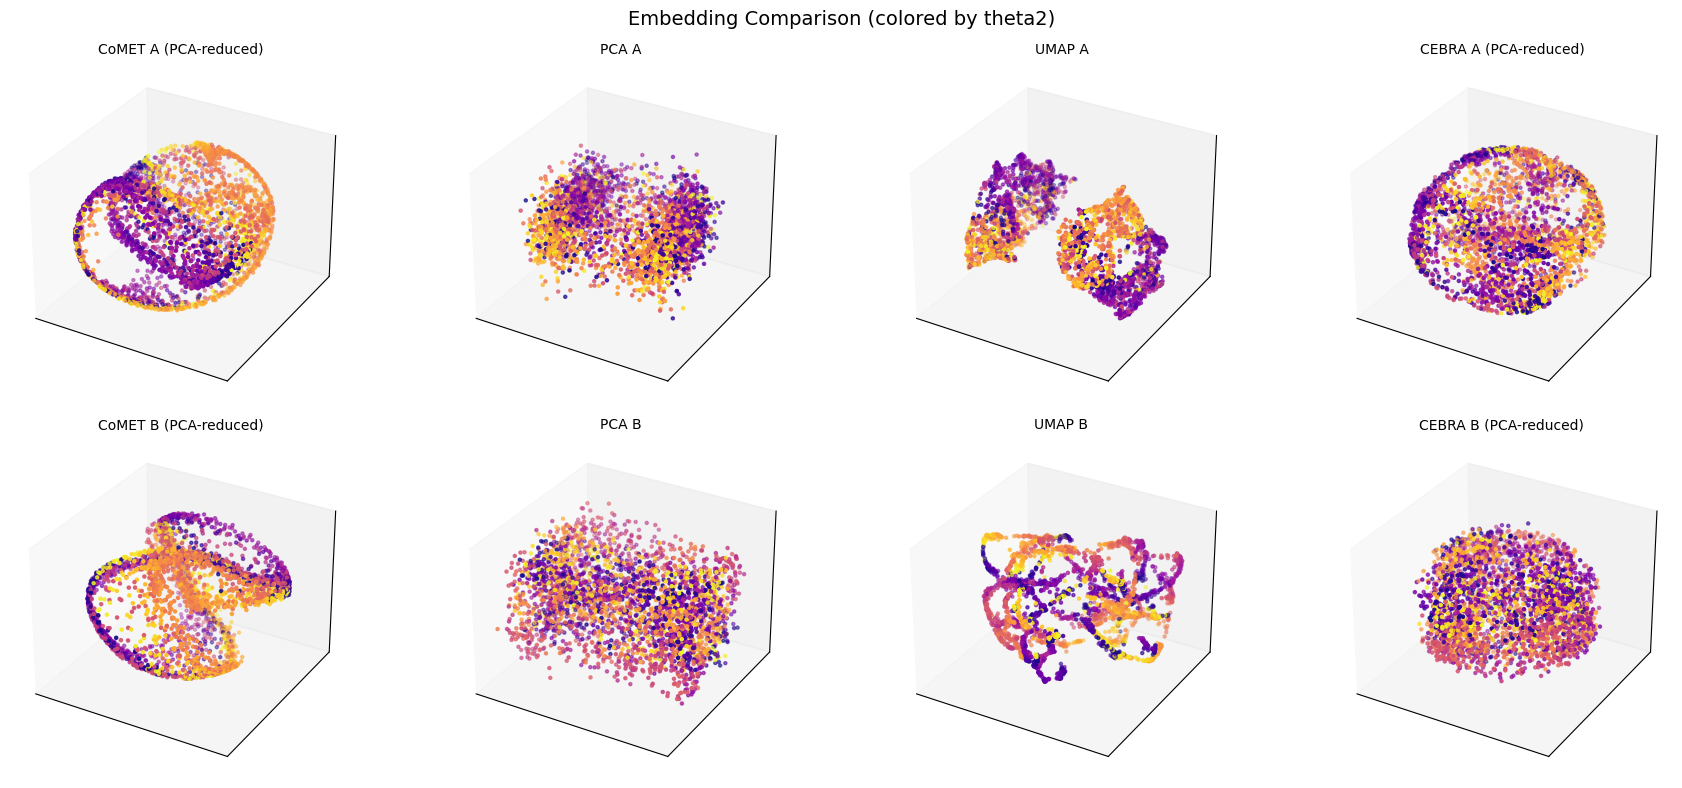

In [11]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa
from sklearn.decomposition import PCA
import numpy as np

# assume you already have:
# ZA, ZB (CoMET)
# ZA_cebra, ZB_cebra (CEBRA)
# Z1_pca, Z2_pca (PCA)
# Z1_umap, Z2_umap (UMAP)
# theta1 (color variable)

def reduce3(Z):
    """Return a 3-D PCA projection regardless of input dim."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z[:, 0], Z[:, 1], Z[:, 2]

# ------------------------------------------
# Create figure: 2 rows x 4 columns
# ------------------------------------------
fig = plt.figure(figsize=(18, 8))

titles_top = ["CoMET A (PCA-reduced)", "PCA A", "UMAP A", "CEBRA A (PCA-reduced)"]
titles_bot = ["CoMET B (PCA-reduced)", "PCA B", "UMAP B", "CEBRA B (PCA-reduced)"]

# Apply PCA to CoMET / CEBRA before plotting
ZA_red = PCA(n_components=3).fit_transform(ZA)
ZB_red = PCA(n_components=3).fit_transform(ZB)
ZA_cebra_red = PCA(n_components=3).fit_transform(ZA_cebra)
ZB_cebra_red = PCA(n_components=3).fit_transform(ZB_cebra)

datasets_top = [ZA_red, Z1_pca, Z1_umap, ZA_cebra_red]
datasets_bot = [ZB_red, Z2_pca, Z2_umap, ZB_cebra_red]

for i in range(4):
    # ---- Top row (view A) ----
    ax = fig.add_subplot(2, 4, i + 1, projection='3d')
    X, Y, Z = reduce3(datasets_top[i])
    ax.scatter(X, Y, Z, c=theta2, cmap='plasma', s=5)
    ax.set_title(titles_top[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

    # ---- Bottom row (view B) ----
    ax = fig.add_subplot(2, 4, i + 5, projection='3d')
    X, Y, Z = reduce3(datasets_bot[i])
    ax.scatter(X, Y, Z, c=theta2,cmap='plasma', s=5)
    ax.set_title(titles_bot[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

fig.suptitle("Embedding Comparison (colored by theta2)", fontsize=14)
plt.tight_layout()
plt.show()


In [12]:
# 6) Decoding: predict latent angles from embeddings
# We'll use Ridge regression to predict sin/cos of angle for circular decoding,
# then compute mean R^2 on sin and cos.

from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

In [13]:

def circular_decode_score(Z, ang):
    Z = np.asarray(Z)
    y = np.stack([np.sin(ang), np.cos(ang)], axis=1)
    n = len(ang)
    ntr = int(0.7 * n)
    Xtr, Xte = Z[:ntr], Z[ntr:]
    ytr, yte = y[:ntr], y[ntr:]
    model = Ridge(alpha=1.0)
    model.fit(Xtr, ytr)
    yhat = model.predict(Xte)
    r2_sin = r2_score(yte[:, 0], yhat[:, 0])
    r2_cos = r2_score(yte[:, 1], yhat[:, 1])
    return (r2_sin + r2_cos) / 2

scores = {}
toval = theta1
scores['CoMETs_A'] = circular_decode_score(ZA, toval)
scores['CoMETs_B'] = circular_decode_score(ZB, toval)
scores['PCA_A']   = circular_decode_score(Z1_pca, toval)
scores['PCA_B']   = circular_decode_score(Z2_pca, toval)
scores['UMAP_A']  = circular_decode_score(Z1_umap, toval)
scores['UMAP_B']  = circular_decode_score(Z2_umap, toval)
scores['CEBRA_A'] = circular_decode_score(ZA_cebra, toval)
scores['CEBRA_B'] = circular_decode_score(ZB_cebra, toval)

print("Decoding scores (mean R2 on sin/cos):")
for k, v in scores.items():
    print(f"{k:10s}: {v:.3f}")


Decoding scores (mean R2 on sin/cos):
CoMETs_A  : 0.921
CoMETs_B  : 0.898
PCA_A     : 0.821
PCA_B     : 0.097
UMAP_A    : 0.833
UMAP_B    : 0.507
CEBRA_A   : 0.902
CEBRA_B   : 0.363


In [14]:

def circular_decode_score(Z, ang):
    Z = np.asarray(Z)
    y = np.stack([np.sin(ang), np.cos(ang)], axis=1)
    n = len(ang)
    ntr = int(0.7 * n)
    Xtr, Xte = Z[:ntr], Z[ntr:]
    ytr, yte = y[:ntr], y[ntr:]
    model = Ridge(alpha=1.0)
    model.fit(Xtr, ytr)
    yhat = model.predict(Xte)
    r2_sin = r2_score(yte[:, 0], yhat[:, 0])
    r2_cos = r2_score(yte[:, 1], yhat[:, 1])
    return (r2_sin + r2_cos) / 2

scores = {}
toval = theta2
scores['CoMETs_A'] = circular_decode_score(ZA, toval)
scores['CoMETs_B'] = circular_decode_score(ZB, toval)
scores['PCA_A']   = circular_decode_score(Z1_pca, toval)
scores['PCA_B']   = circular_decode_score(Z2_pca, toval)
scores['UMAP_A']  = circular_decode_score(Z1_umap, toval)
scores['UMAP_B']  = circular_decode_score(Z2_umap, toval)
scores['CEBRA_A'] = circular_decode_score(ZA_cebra, toval)
scores['CEBRA_B'] = circular_decode_score(ZB_cebra, toval)

print("Decoding scores (mean R2 on sin/cos):")
for k, v in scores.items():
    print(f"{k:10s}: {v:.3f}")


Decoding scores (mean R2 on sin/cos):
CoMETs_A  : 0.174
CoMETs_B  : 0.159
PCA_A     : 0.112
PCA_B     : -0.007
UMAP_A    : 0.054
UMAP_B    : -0.004
CEBRA_A   : 0.406
CEBRA_B   : 0.101


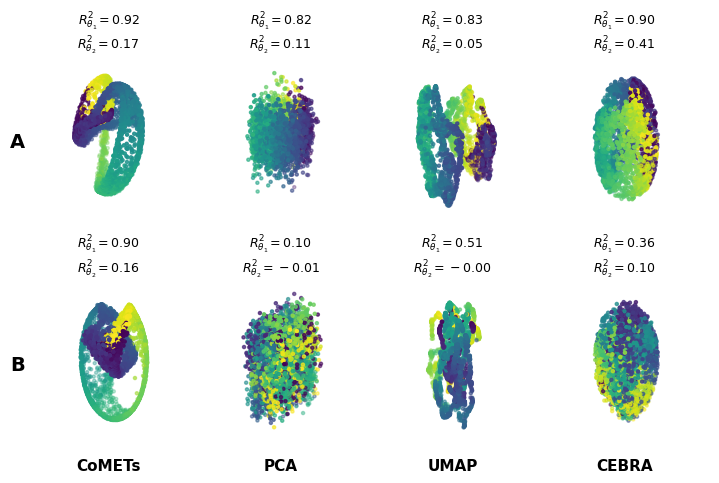

In [15]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
import numpy as np

# ----------------------------------------------------------
# circular decoding function (your definition)
# ----------------------------------------------------------
def circular_decode_score(Z, ang):
    Z = np.asarray(Z)
    y = np.stack([np.sin(ang), np.cos(ang)], axis=1)
    n = len(ang)
    ntr = int(0.7 * n)
    Xtr, Xte = Z[:ntr], Z[ntr:]
    ytr, yte = y[:ntr], y[ntr:]
    model = Ridge(alpha=1.0)
    model.fit(Xtr, ytr)
    yhat = model.predict(Xte)
    r2_sin = r2_score(yte[:, 0], yhat[:, 0])
    r2_cos = r2_score(yte[:, 1], yhat[:, 1])
    return (r2_sin + r2_cos) / 2

# ----------------------------------------------------------
# helper
# ----------------------------------------------------------
def reduce3(Z):
    """Guarantee 3-D PCA projection."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z

# ----------------------------------------------------------
# Compute decoding R²θ1 and R²θ2 for each model × modality
# ----------------------------------------------------------
models = {
    "CoMETs": (ZA, ZB),
    "PCA": (Z1_pca, Z2_pca),
    "UMAP": (Z1_umap, Z2_umap),
    "CEBRA": (ZA_cebra, ZB_cebra),
}

scores = {}
for name, (ZA_mod, ZB_mod) in models.items():
    scores[f"{name}_A_theta1"] = circular_decode_score(ZA_mod, theta1)
    scores[f"{name}_B_theta1"] = circular_decode_score(ZB_mod, theta1)
    scores[f"{name}_A_theta2"] = circular_decode_score(ZA_mod, theta2)
    scores[f"{name}_B_theta2"] = circular_decode_score(ZB_mod, theta2)

# ----------------------------------------------------------
# Plot setup (poster layout)
# ----------------------------------------------------------
fig = plt.figure(figsize=(14, 8))  # slightly taller
labels = list(models.keys())
datasets_A = [reduce3(models[m][0]) for m in labels]
datasets_B = [reduce3(models[m][1]) for m in labels]
angles = [(25, 40)] * len(labels)

for i, name in enumerate(labels):
    # --- Top row: Modality A ---
    axA = fig.add_subplot(2, 4, i + 1, projection="3d")
    Z = datasets_A[i]
    axA.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c=theta1, cmap="viridis", s=5)
    axA.view_init(*angles[i])
    axA.set_axis_off()
    axA.set_facecolor("none")
    axA.set_box_aspect([1, 1, 2])   # vertically stretched
    axA.set_title(
        rf"$R^2_{{\theta_1}}={scores[f'{name}_A_theta1']:.2f}$" + "\n" +
        rf"$R^2_{{\theta_2}}={scores[f'{name}_A_theta2']:.2f}$",
        fontsize=9
    )
    if i == 0:
        axA.text2D(-0.08, 0.5, "A", transform=axA.transAxes,
                   fontsize=14, fontweight="bold", va="center")

    # --- Bottom row: Modality B ---
    axB = fig.add_subplot(2, 4, i + 5, projection="3d")
    Z = datasets_B[i]
    axB.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c=theta1, cmap="viridis", s=5)
    axB.view_init(*angles[i])
    axB.set_axis_off()
    axB.set_facecolor("none")
    axB.set_box_aspect([1, 1, 2])   # vertically stretched
    axB.set_title(
        rf"$R^2_{{\theta_1}}={scores[f'{name}_B_theta1']:.2f}$" + "\n" +
        rf"$R^2_{{\theta_2}}={scores[f'{name}_B_theta2']:.2f}$",
        fontsize=9
    )
    axB.text2D(0.5, -0.12, name, transform=axB.transAxes,
               fontsize=11, fontweight="bold", ha="center")
    if i == 0:
        axB.text2D(-0.08, 0.5, "B", transform=axB.transAxes,
                   fontsize=14, fontweight="bold", va="center")
plt.subplots_adjust(wspace=0.01, hspace=0.03,
                    left=0.01, right=0.5, top=0.6, bottom=0.05)
plt.show()


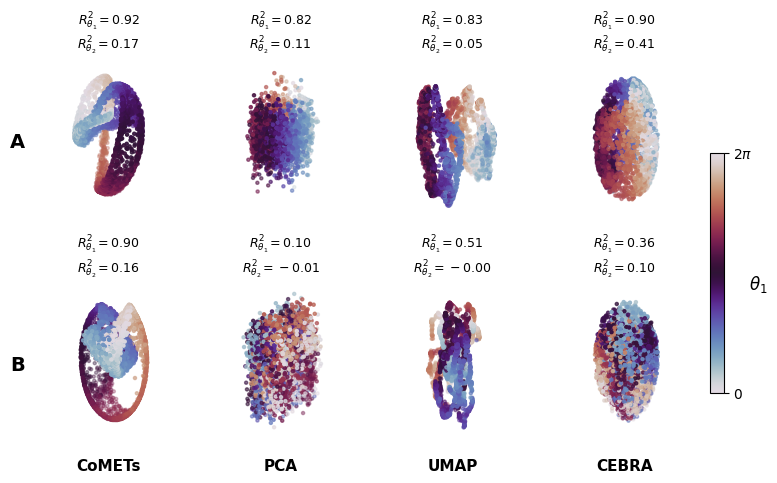

: 

In [ ]:
# ----------------------------------------------------------
# Plot setup (poster layout)
# ----------------------------------------------------------
fig = plt.figure(figsize=(14, 8))
labels = list(models.keys())
datasets_A = [reduce3(models[m][0]) for m in labels]
datasets_B = [reduce3(models[m][1]) for m in labels]
angles = [(25, 40)] * len(labels)

all_axes = []  # 🟩 collect axes for colorbar

for i, name in enumerate(labels):
    # --- Top row: Modality A ---
    axA = fig.add_subplot(2, 4, i + 1, projection="3d")
    Z = datasets_A[i]
    p = axA.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c=theta1, cmap="twilight", s=5)
    axA.view_init(*angles[i])
    axA.set_axis_off()
    axA.set_facecolor("none")
    axA.set_box_aspect([1, 1, 2])
    all_axes.append(axA)

    axA.set_title(
        rf"$R^2_{{\theta_1}}={scores[f'{name}_A_theta1']:.2f}$" + "\n" +
        rf"$R^2_{{\theta_2}}={scores[f'{name}_A_theta2']:.2f}$",
        fontsize=9
    )
    if i == 0:
        axA.text2D(-0.08, 0.5, "A", transform=axA.transAxes,
                   fontsize=14, fontweight="bold", va="center")

    # --- Bottom row: Modality B ---
    axB = fig.add_subplot(2, 4, i + 5, projection="3d")
    Z = datasets_B[i]
    p = axB.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c=theta1, cmap="twilight", s=5)
    axB.view_init(*angles[i])
    axB.set_axis_off()
    axB.set_facecolor("none")
    axB.set_box_aspect([1, 1, 2])
    all_axes.append(axB)

    axB.set_title(
        rf"$R^2_{{\theta_1}}={scores[f'{name}_B_theta1']:.2f}$" + "\n" +
        rf"$R^2_{{\theta_2}}={scores[f'{name}_B_theta2']:.2f}$",
        fontsize=9
    )
    axB.text2D(0.5, -0.12, name, transform=axB.transAxes,
               fontsize=11, fontweight="bold", ha="center")
    if i == 0:
        axB.text2D(-0.08, 0.5, "B", transform=axB.transAxes,
                   fontsize=14, fontweight="bold", va="center")

# 🟩 Add a shared colorbar for θ (explicit position)

sm = plt.cm.ScalarMappable(cmap="twilight", norm=plt.Normalize(vmin=0, vmax=2*np.pi))
sm.set_array([])

# Explicit position [x0, y0, width, height]
cbar_ax = fig.add_axes([0.5, 0.15, 0.01, 0.3])
cbar = fig.colorbar(sm, cax=cbar_ax)

# Label and tick setup
cbar.set_label(r'$\theta_1$', fontsize=12, labelpad=4,rotation=0)

# Define ticks from 0 to 2π
ticks = [0, 2*np.pi]
tick_labels = [r'$0$', r'$2\pi$']
cbar.set_ticks(ticks)
cbar.set_ticklabels(tick_labels)
cbar.ax.tick_params(labelsize=10)


plt.subplots_adjust(wspace=0.01, hspace=0.03, left=0.01, right=0.5, top=0.6, bottom=0.05)
plt.show()
